In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Netflix dataset
df = pd.read_csv('/content/netflix_titles.csv')

# Display first five rows
df.head()


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [ ]:

# Dataset dimensions
print("Dataset shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types and non-null values
df.info()

# Statistical summary
df.describe(include='all')


Dataset shape: (8807, 12)

Columns:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,Zubaan,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


In [ ]:

# Count missing values in every column
print(df.isnull().sum())

# Calculate missing-value percentages
missing_percent = (
    df.isnull().sum() / len(df) * 100
).sort_values(ascending=False)

print(missing_percent)


show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64
director        29.908028
country          9.435676
cast             9.367549
date_added       0.113546
rating           0.045418
duration         0.034064
show_id          0.000000
type             0.000000
title            0.000000
release_year     0.000000
listed_in        0.000000
description      0.000000
dtype: float64


In [ ]:

# Create a working copy
df_clean = df.copy()

# Fill missing text fields
text_columns = ['director', 'cast', 'country', 'rating']

for col in text_columns:
    df_clean[col] = df_clean[col].fillna('Unknown')

# Remove records missing important fields
df_clean = df_clean.dropna(
    subset=['date_added', 'duration']
)

# Convert date_added into datetime format
df_clean['date_added'] = pd.to_datetime(
    df_clean['date_added'],
    errors='coerce'
)

# Check the cleaned dataset
print("Cleaned shape:", df_clean.shape)
print(df_clean.isnull().sum())


Cleaned shape: (8794, 12)
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      88
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64


In [ ]:

# Check rows where date_added is missing
print("Missing dates:", df_clean['date_added'].isnull().sum())

# Remove rows with invalid or missing dates
df_clean = df_clean.dropna(subset=['date_added']).copy()

# Verify the result
print("Final dataset shape:", df_clean.shape)
print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Missing dates: 88
Final dataset shape: (8706, 12)

Remaining missing values:
show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
description     0
dtype: int64


In [12]:

# Step 6: Check duplicates

print("Total duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nDataset shape:", df.shape)



Total duplicate rows: 0

Data types:
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

Dataset shape: (8807, 12)


In [13]:

# Step 7: Create a copy for cleaning

df_clean = df.copy()

# Fill missing values in selected text columns
text_columns = ["director", "cast", "country", "rating"]

for col in text_columns:
    df_clean[col] = df_clean[col].fillna("Unknown")

# Convert date_added to datetime
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"].str.strip(),
    format="mixed",
    errors="coerce"
)

# Remove duplicate rows if any
df_clean = df_clean.drop_duplicates()

print("Cleaning completed!")
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())


Cleaning completed!
Original shape: (8807, 12)
Cleaned shape: (8807, 12)

Remaining missing values:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         3
listed_in        0
description      0
dtype: int64


In [14]:

# Step 8: Handle remaining missing values

# Fill missing dates with NaT (keep as missing)
# Fill missing duration values with "Unknown"
df_clean["duration"] = df_clean["duration"].fillna("Unknown")

# Check missing values again
print("Missing values after handling:")
print(df_clean.isnull().sum())

# Check data types
print("\nColumn data types:")
print(df_clean.dtypes)


Missing values after handling:
show_id          0
type             0
title            0
director         0
cast             0
country          0
date_added      10
release_year     0
rating           0
duration         0
listed_in        0
description      0
dtype: int64

Column data types:
show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object


type
Movie      6131
TV Show    2676
Name: count, dtype: int64


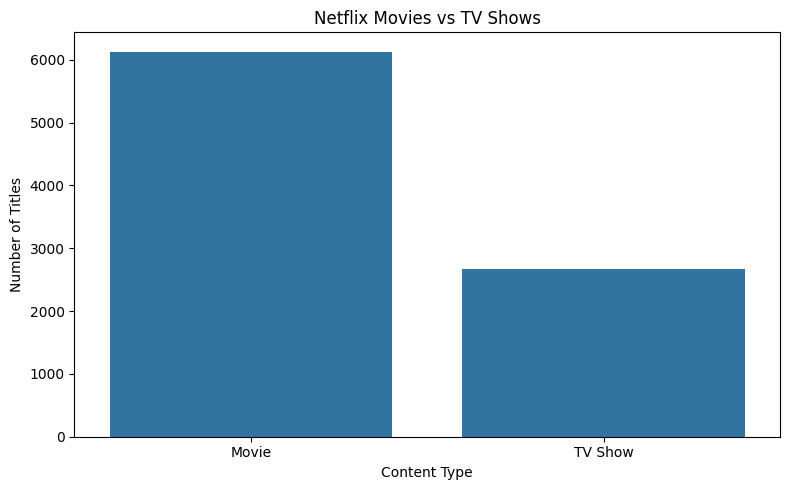

In [15]:
#Analyze Movies vs TV Shows


# Step 8: Content type analysis

content_counts = df_clean["type"].value_counts()

print(content_counts)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=content_counts.index,
    y=content_counts.values
)

plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


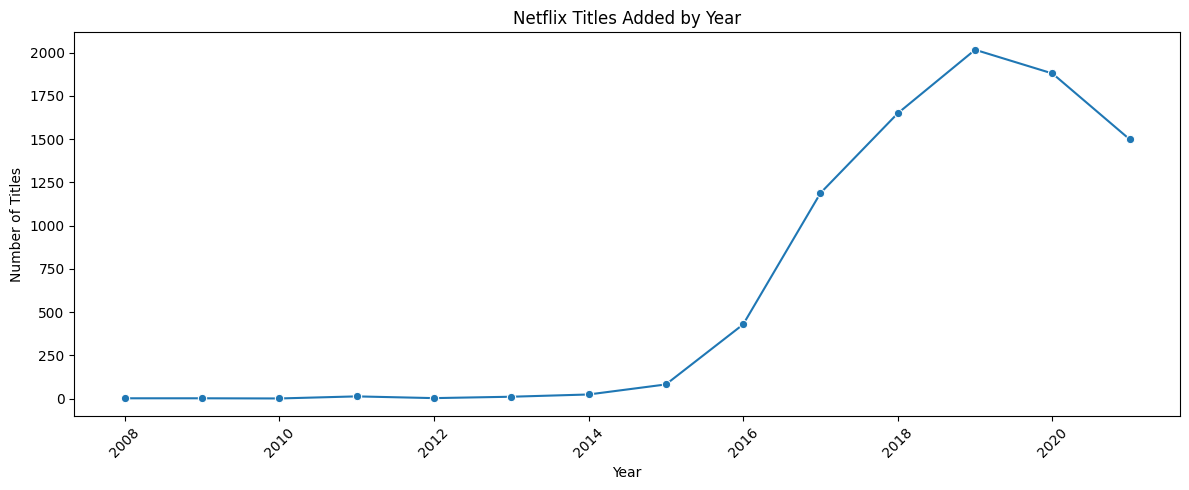

In [16]:
#Analyze content added by year


# Step 9: Titles added by year

df_clean["year_added"] = df_clean["date_added"].dt.year

year_counts = (
    df_clean["year_added"]
    .dropna()
    .astype(int)
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(12, 5))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    marker="o"
)

plt.title("Netflix Titles Added by Year")
plt.xlabel("Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:
#Find the top 10 countries

# Step 10: Top 10 countries

countries = (
    df_clean.loc[df_clean["country"] != "Unknown", "country"]
    .str.split(", ")
    .explode()
)

top_countries = countries.value_counts().head(10)

print(top_countries)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_countries.values,
    y=top_countries.index
)

plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Titles")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


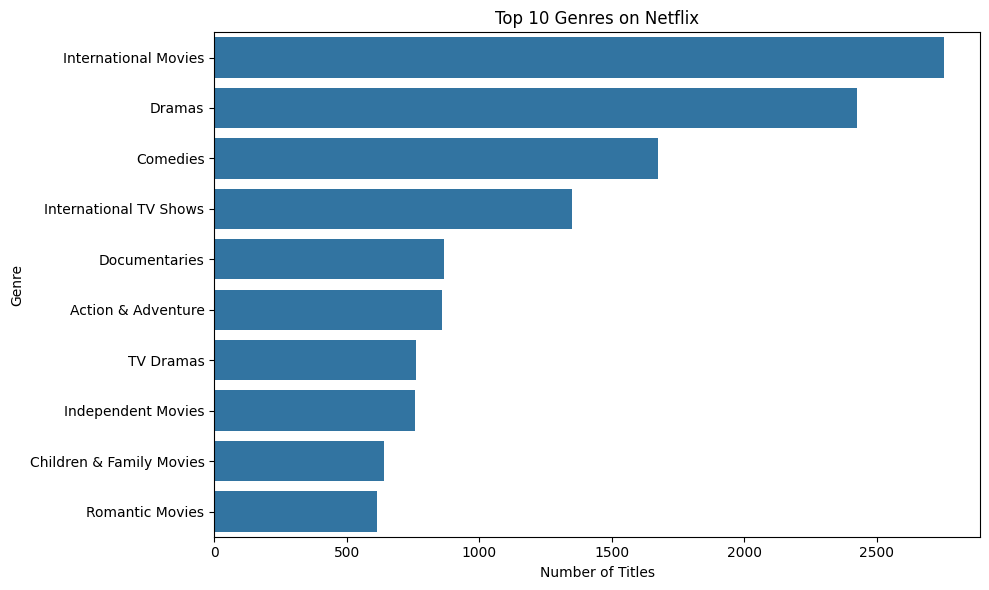

In [17]:
#Analyze the most common genres

# Step 11: Top 10 genres

genres = (
    df_clean["listed_in"]
    .dropna()
    .str.split(", ")
    .explode()
)

top_genres = genres.value_counts().head(10)

print(top_genres)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_genres.values,
    y=top_genres.index
)

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()


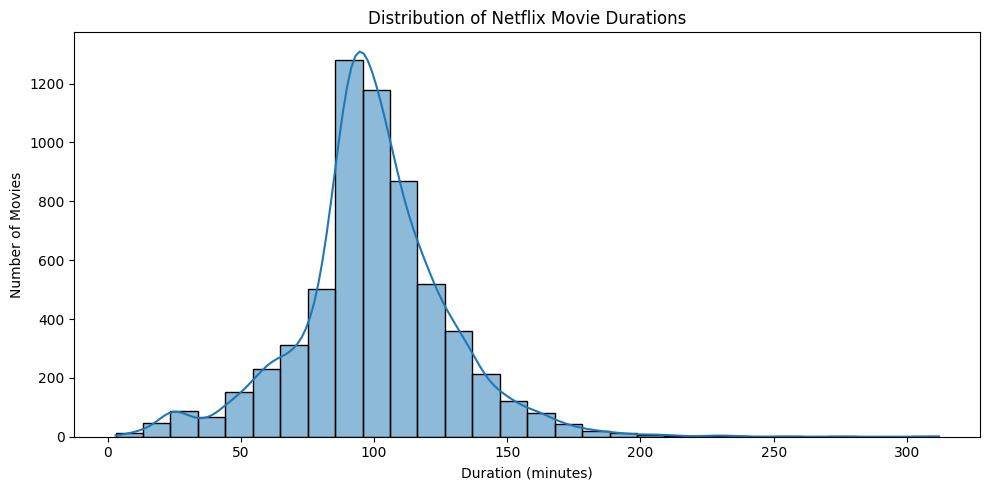

Median movie duration: 98.0 minutes


In [18]:
#Analyze movie durations

# Step 12: Movie duration analysis

movies = df_clean[df_clean["type"] == "Movie"].copy()

movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=movies,
    x="duration_minutes",
    bins=30,
    kde=True
)

plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

print(
    "Median movie duration:",
    movies["duration_minutes"].median(),
    "minutes"
)


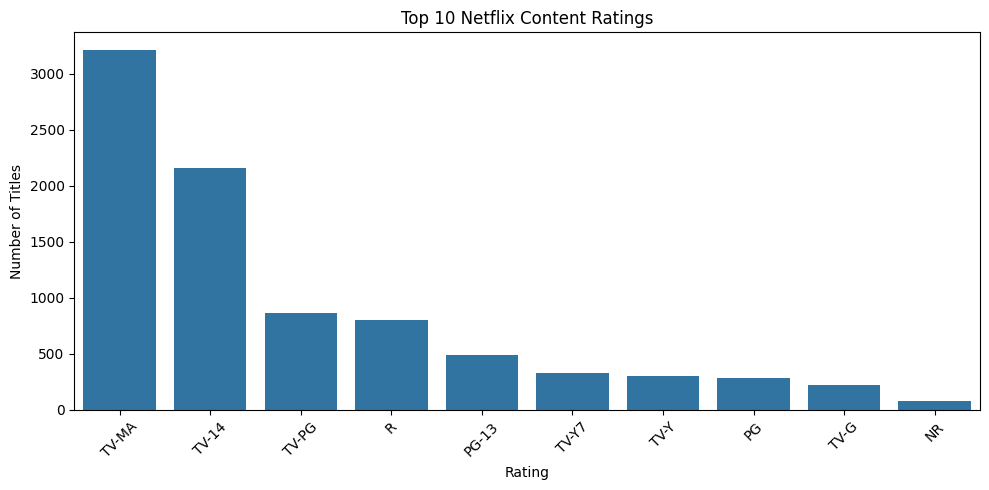

In [19]:
 #Find the most common ratings

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="rating",
    order=df_clean["rating"].value_counts().index[:10]
)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [20]:
# Savind cleaned data set

df_clean.to_csv(
    "/content/netflix_titles_cleaned.csv",
    index=False
)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [21]:

from google.colab import files

files.download("/content/netflix_titles_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

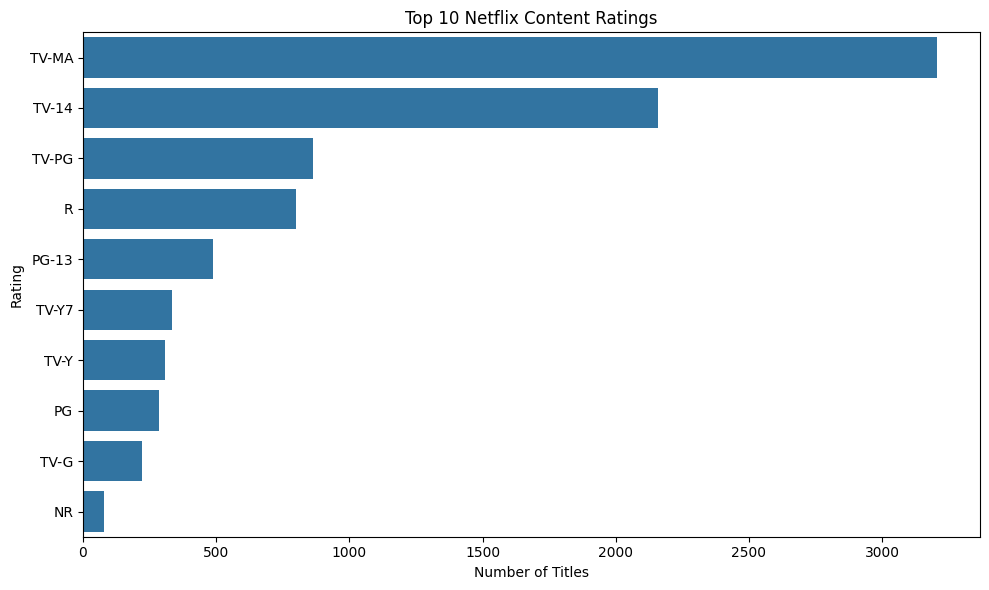

,count
rating,
TV-MA,3207
TV-14,2160
TV-PG,863
R,799
PG-13,490
TV-Y7,334
TV-Y,307
PG,287
TV-G,220


In [22]:
#Analyze Netflix content ratings

rating_counts = df_clean["rating"].value_counts()
rating_counts = rating_counts.drop("Unknown", errors="ignore").head(10)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

display(rating_counts)


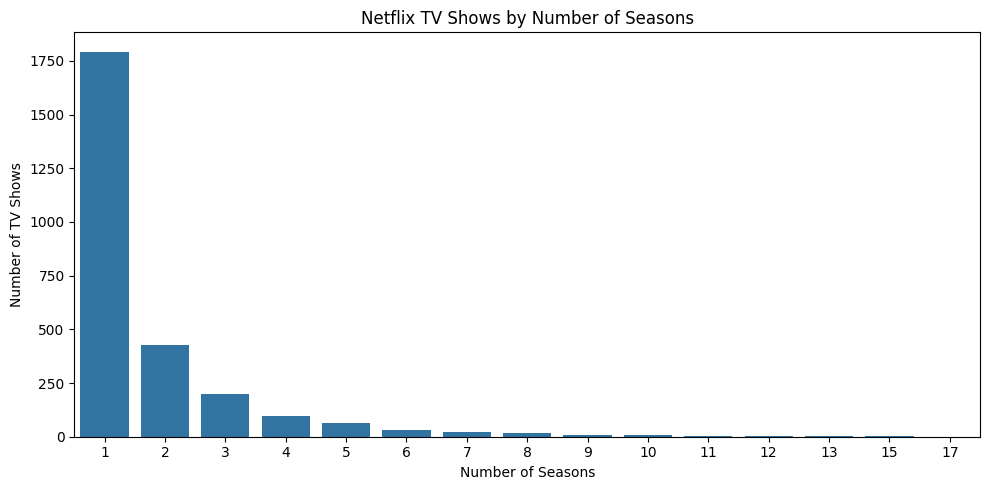

Median number of seasons: 1.0


In [23]:
#Analyze TV show seasons

tv_shows = df_clean[
    (df_clean["type"] == "TV Show") &
    (df_clean["duration"].str.contains("Season", na=False))
].copy()

tv_shows["seasons"] = pd.to_numeric(
    tv_shows["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

season_counts = tv_shows["seasons"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    x=season_counts.index,
    y=season_counts.values
)

plt.title("Netflix TV Shows by Number of Seasons")
plt.xlabel("Number of Seasons")
plt.ylabel("Number of TV Shows")
plt.tight_layout()
plt.show()

print("Median number of seasons:", tv_shows["seasons"].median())


Median years between release and catalog addition: 1.0


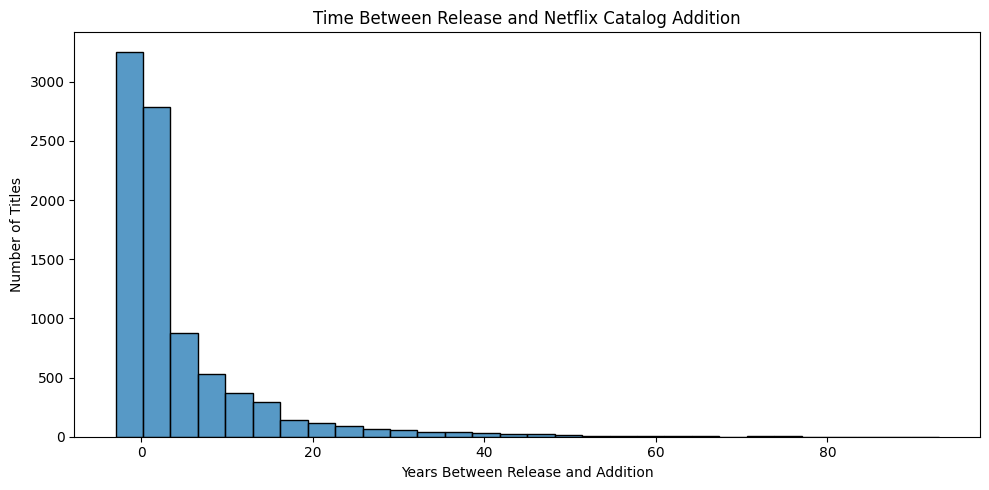

In [24]:

 # Release year vs year added

trend_df = df_clean.dropna(
    subset=["release_year", "year_added"]
).copy()

trend_df["years_until_added"] = (
    trend_df["year_added"] - trend_df["release_year"]
)

print("Median years between release and catalog addition:",
      trend_df["years_until_added"].median())

plt.figure(figsize=(10, 5))
sns.histplot(
    data=trend_df,
    x="years_until_added",
    bins=30
)

plt.title("Time Between Release and Netflix Catalog Addition")
plt.xlabel("Years Between Release and Addition")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()


In [26]:

# Project KPIs

total_titles = len(df_clean)
total_movies = (df_clean["type"] == "Movie").sum()
total_tv_shows = (df_clean["type"] == "TV Show").sum()
unique_countries = (
    df_clean.loc[df_clean["country"] != "Unknown", "country"]
    .str.split(", ")
    .explode()
    .nunique()
)

print("========== NETFLIX DATA ANALYSIS ==========")
print("Total titles:", total_titles)
print("Total movies:", total_movies)
print("Total TV shows:", total_tv_shows)
print("Unique countries represented:", unique_countries)
print("Movie percentage:", round(total_movies / total_titles * 100, 2), "%")
print("TV show percentage:", round(total_tv_shows / total_titles * 100, 2), "%")
print("===========================================")



========== NETFLIX DATA ANALYSIS ==========
Total titles: 8807
Total movies: 6131
Total TV shows: 2676
Unique countries represented: 127
Movie percentage: 69.62 %
TV show percentage: 30.38 %


In [29]:
 #Saving charts for GitHub
 plt.savefig(
    "/content/chart_name.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

<Figure size 640x480 with 0 Axes>

In [31]:
from google.colab import files

files.download("/content/netflix_ratings.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

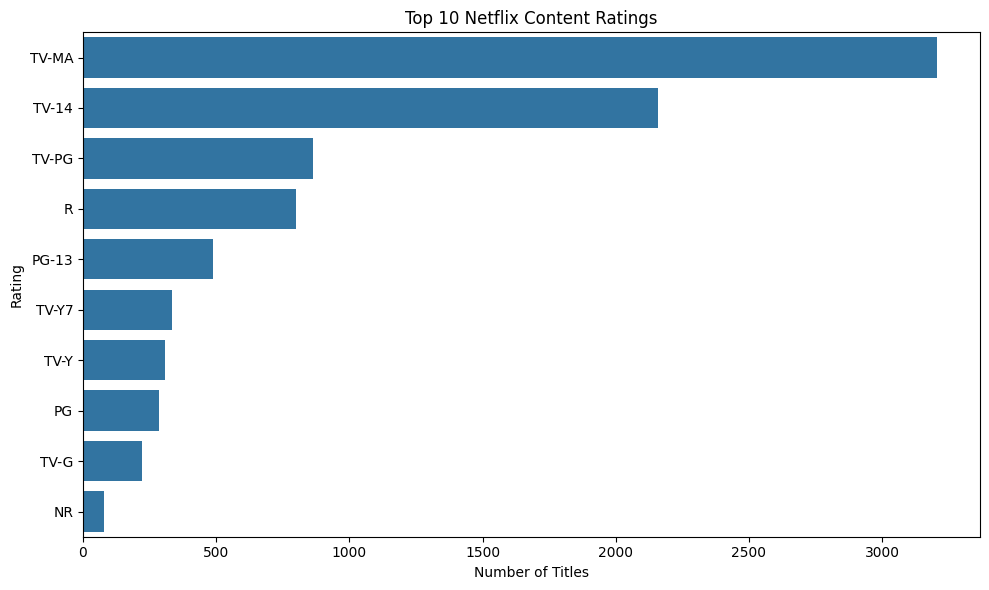

Chart saved successfully!


In [30]:
#Create and save the ratings chart

# Create the Netflix ratings chart

import matplotlib.pyplot as plt
import seaborn as sns

rating_counts = df_clean["rating"].value_counts()
rating_counts = rating_counts.drop(
    "Unknown", errors="ignore"
).head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=rating_counts.values,
    y=rating_counts.index
)

plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()

# Save the chart BEFORE showing it
plt.savefig(
    "/content/netflix_ratings.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


In [32]:

# Create a folder for all project charts

import os
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

output_dir = "/content/netflix_outputs"
os.makedirs(output_dir, exist_ok=True)

# 1. Movies vs TV Shows
plt.figure(figsize=(8, 5))
sns.countplot(data=df_clean, x="type")
plt.title("Netflix Movies vs TV Shows")
plt.xlabel("Content Type")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig(f"{output_dir}/content_by_type.png", dpi=300)
plt.close()

# 2. Titles added by year
if "year_added" not in df_clean.columns:
    df_clean["year_added"] = df_clean["date_added"].dt.year

year_counts = (
    df_clean["year_added"].dropna().astype(int)
    .value_counts().sort_index()
)

plt.figure(figsize=(12, 5))
sns.lineplot(x=year_counts.index, y=year_counts.values, marker="o")
plt.title("Netflix Titles Added by Year")
plt.xlabel("Year Added")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.savefig(f"{output_dir}/titles_added_by_year.png", dpi=300)
plt.close()

# 3. Top countries
countries = (
    df_clean.loc[df_clean["country"] != "Unknown", "country"]
    .dropna().str.split(", ").explode()
)
top_countries = countries.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title("Top 10 Countries by Netflix Titles")
plt.xlabel("Number of Title-Country Associations")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig(f"{output_dir}/top_countries.png", dpi=300)
plt.close()

# 4. Top genres
genres = df_clean["listed_in"].dropna().str.split(", ").explode()
top_genres = genres.value_counts().head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_genres.values, y=top_genres.index)
plt.title("Top 10 Netflix Genres")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.savefig(f"{output_dir}/top_genres.png", dpi=300)
plt.close()

# 5. Content ratings
rating_counts = df_clean["rating"].value_counts()
rating_counts = rating_counts.drop("Unknown", errors="ignore").head(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=rating_counts.values, y=rating_counts.index)
plt.title("Top 10 Netflix Content Ratings")
plt.xlabel("Number of Titles")
plt.ylabel("Rating")
plt.tight_layout()
plt.savefig(f"{output_dir}/netflix_ratings.png", dpi=300)
plt.close()

# 6. Movie durations
movies = df_clean[df_clean["type"] == "Movie"].copy()
movies["duration_minutes"] = pd.to_numeric(
    movies["duration"].str.extract(r"(\d+)")[0],
    errors="coerce"
)

plt.figure(figsize=(10, 5))
sns.histplot(movies["duration_minutes"].dropna(), bins=30, kde=True)
plt.title("Distribution of Netflix Movie Durations")
plt.xlabel("Duration (minutes)")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.savefig(f"{output_dir}/movie_durations.png", dpi=300)
plt.close()

print("Charts saved:", os.listdir(output_dir))


Charts saved: ['content_by_type.png', 'netflix_ratings.png', 'top_countries.png', 'top_genres.png', 'titles_added_by_year.png', 'movie_durations.png']


In [34]:
# downloarding
import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/netflix_outputs",
    "zip",
    "/content/netflix_outputs"
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
# dowloarding complet notebook
from google.colab import files

files.download("/content/netflix_titles_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>